# Error budget at the buoys (2013)

Where the error of the reconstruction comes from, at the 27 buoys with Hs in 2013
(SnapWave, MDA 600, CODEC water level, both offshore sources). Estimates at each buoy:

| estimate | what it is |
| --- | --- |
| `offshore` | the hindcast at the buoy's closest goal (no propagation) |
| `metamodel bulk` | linear sum of the goals forced by their bulk sea state |
| `metamodel spectral` | linear sum of the goals x offshore partitions: **the product** |
| `dynamic no wind` | SnapWave every hour, all goals, CODEC, bulk forcing, no wind |
| `dynamic wind` | the same with the ERA5 wind field |

The dynamic runs force each goal with its bulk sea state, so `metamodel bulk` vs
`dynamic no wind` is like for like: that difference is the **method error**. The total
error of the product splits exactly into:

`spectral − buoy = (spectral − bulk) + (bulk − dynamic no wind) + (no wind − wind) + (dynamic wind − buoy)`

i.e. partitions + method + missing wind + model and forcing. Metrics are reference first
(bias = estimate − reference). Hours where SnapWave with wind did not converge are NaN in
`dynamic wind`; the budget only uses pairs valid in every estimate.

In [ ]:
import sys

sys.path.insert(0, "..")  # the case folder (utils/)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import results as rs
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)

In [2]:
buoy = rs.buoys()
estimates = {off: rs.estimates_at_buoys(off, buoy) for off in rs.OFFSHORE}
for off, est in estimates.items():
    print(f"{off}: {list(est)}")
print(f"{buoy.sizes['sites']} buoys with Hs in {rs.YEAR}")

WHACS: ['offshore', 'metamodel bulk', 'metamodel spectral', 'dynamic no wind', 'dynamic wind']
WHACS_cal: ['offshore', 'metamodel bulk', 'metamodel spectral', 'dynamic no wind', 'dynamic wind']
27 buoys with Hs in 2013


## 1 · Skill at the buoys

Median over buoys of the per-buoy metrics, every pair valid in the buoy and the estimate
(so `dynamic wind` has fewer pairs: its non-converged hours).

In [ ]:
for off, est in estimates.items():
    for variable in rs.VARIABLES:
        if variable not in buoy or int(buoy[variable].notnull().sum()) == 0:
            continue
        table = rs.median_metrics(buoy, est, variable)[
            ["n", "bias", "rmse", "si", "r2"]
        ]
        print(
            f"{off} · {variable} ({int((buoy[variable].notnull().any('time')).sum())} buoys)"
        )
        display(table)

WHACS · hs (27 buoys)


,n,bias,rmse,si,r2
offshore,7065.0,0.248,0.392,0.277,0.502
metamodel bulk,7065.0,-0.202,0.376,0.250,0.635
metamodel spectral,7065.0,-0.170,0.353,0.253,0.692
dynamic no wind,7065.0,-0.199,0.349,0.245,0.647
dynamic wind,6727.0,0.112,0.284,0.199,0.805


WHACS · tp (25 buoys)


,n,bias,rmse,si,r2
offshore,7548.0,0.453,1.959,0.304,-0.433
metamodel bulk,7546.0,0.542,2.207,0.335,-0.817
metamodel spectral,7545.0,1.177,3.145,0.450,-1.919
dynamic no wind,7548.0,0.819,2.017,0.291,-0.587
dynamic wind,7147.0,0.627,1.616,0.235,0.055


WHACS · dir (15 buoys)


,n,bias,rmse,si,r2
offshore,6940.0,4.928,29.231,NaN,0.710
metamodel bulk,6940.0,3.491,27.189,NaN,0.795
metamodel spectral,6940.0,6.324,36.564,NaN,0.608
dynamic no wind,6940.0,3.445,30.172,NaN,0.736
dynamic wind,6577.0,3.630,22.737,NaN,0.832


... (6 outputs left out)

WHACS_cal · dir (15 buoys)


,n,bias,rmse,si,r2
offshore,6940.0,4.928,29.231,NaN,0.710
metamodel bulk,6940.0,3.513,27.091,NaN,0.795
metamodel spectral,6940.0,5.740,36.034,NaN,0.619
dynamic no wind,6940.0,3.466,29.941,NaN,0.737
dynamic wind,6643.0,3.346,22.512,NaN,0.836


WHACS_cal · spr (10 buoys)


,n,bias,rmse,si,r2
offshore,8491.5,-5.724,11.259,0.239,-0.350
metamodel bulk,8489.0,-17.451,20.478,0.233,-3.535
metamodel spectral,8491.5,-12.438,16.494,0.264,-1.900
dynamic no wind,8491.5,-16.912,20.346,0.252,-3.501
dynamic wind,8168.0,-7.533,11.477,0.205,-0.395


## 2 · The storm tail

Median over buoys of `quantile(estimate) − quantile(buoy)` of Hs. Quantiles compare the
distributions, so they show storm skill without the regression to the mean of binning by
observed Hs.

In [4]:
for off, est in estimates.items():
    print(off)
    display(rs.quantile_bias(buoy, est))

WHACS


quantile,p50,p90,p99,p99.9
offshore,0.239,0.528,0.358,0.336
metamodel bulk,-0.154,-0.203,-0.525,-0.707
metamodel spectral,-0.102,-0.193,-0.515,-0.686
dynamic no wind,-0.137,-0.244,-0.528,-0.976
dynamic wind,0.193,0.207,0.039,-0.443


WHACS_cal


quantile,p50,p90,p99,p99.9
offshore,0.244,0.553,0.745,0.918
metamodel bulk,-0.144,-0.109,-0.269,-0.227
metamodel spectral,-0.102,-0.105,-0.256,-0.223
dynamic no wind,-0.118,-0.150,-0.386,-0.592
dynamic wind,0.188,0.222,0.150,-0.113


## 3 · Error budget

Mean Hs error per part, over all pairs and over classes of each buoy's own Hs quantiles.
The split between parts per class is fair; the class itself is picked by the observation,
so read storm skill from section 2, not from the last column here.

,all,p0-50,p50-90,p90-99,p99-100
partitions (spectral - bulk),0.048,0.067,0.033,0.013,0.007
method (bulk - dynamic no wind),-0.003,-0.003,-0.014,0.027,0.148
missing wind (no wind - wind),-0.307,-0.216,-0.370,-0.510,-0.586
model + forcing (dynamic wind - buoy),0.111,0.127,0.126,0.023,-0.492
total (spectral - buoy),-0.151,-0.024,-0.224,-0.447,-0.924
pairs,183222.000,91564.000,73334.000,16478.000,1846.000


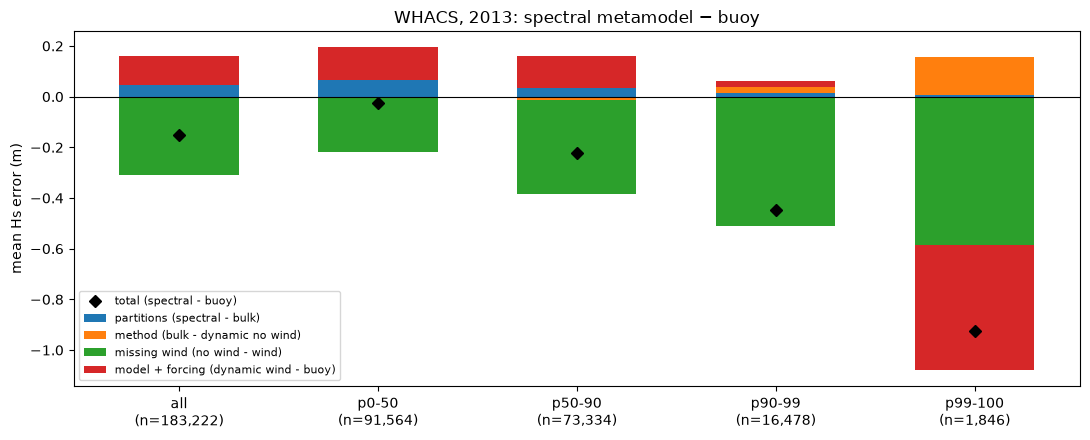

,all,p0-50,p50-90,p90-99,p99-100
partitions (spectral - bulk),0.047,0.066,0.032,0.011,0.006
method (bulk - dynamic no wind),-0.003,-0.005,-0.014,0.031,0.191
missing wind (no wind - wind),-0.294,-0.203,-0.359,-0.489,-0.520
model + forcing (dynamic wind - buoy),0.133,0.137,0.147,0.093,-0.236
total (spectral - buoy),-0.117,-0.004,-0.194,-0.353,-0.558
pairs,184987.000,92538.000,73940.000,16646.000,1863.000


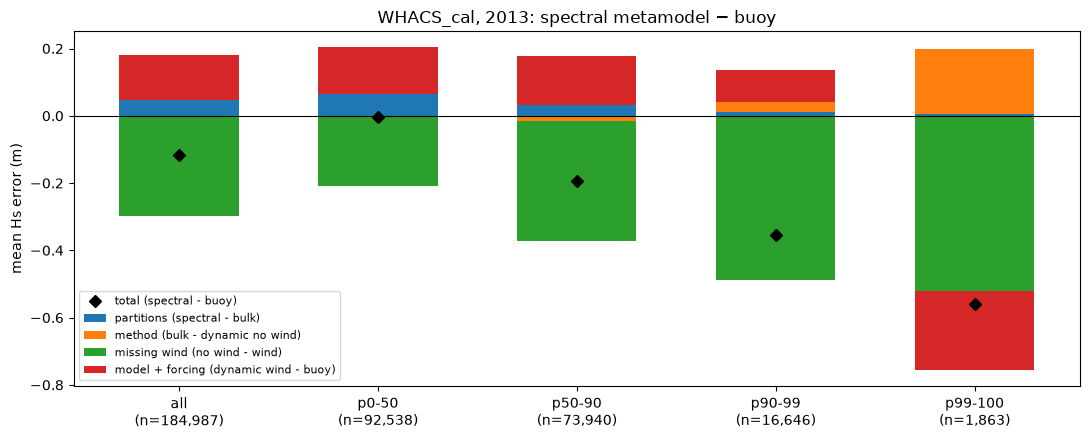

In [5]:
budgets = {}
for off, est in estimates.items():
    budgets[off] = rs.error_budget(buoy, est)
    display(budgets[off].rename(columns=str).style.format(precision=3).set_caption(off))
    rs.plot_budget(budgets[off], title=f"{off}, {rs.YEAR}: spectral metamodel − buoy")
    plt.show()

## 4 · Per buoy

Hs bias of each estimate at each buoy, against the buoy's mesh depth.

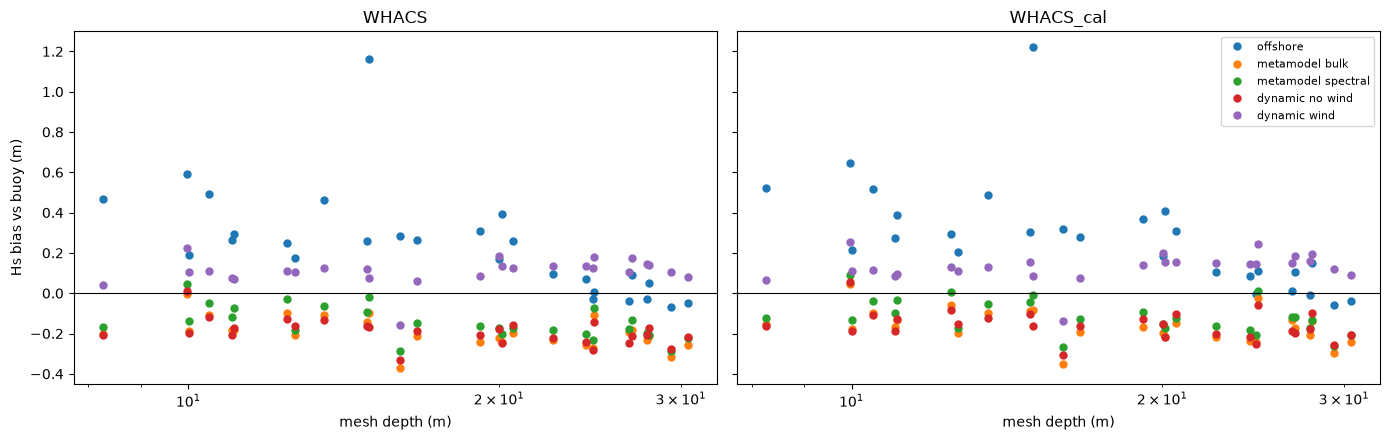

In [ ]:
fig, axes = plt.subplots(
    1, len(estimates), figsize=(7 * len(estimates), 4.5), sharey=True
)
for ax, (off, est) in zip(np.atleast_1d(axes), estimates.items()):
    for name, field in est.items():
        m = rs.site_metrics(buoy, field)
        depth = buoy["site_mesh_depth"].sel(sites=m.index)
        ax.plot(depth, m["bias"], "o", ms=5, label=name)
    ax.axhline(0, color="k", lw=0.8)
    ax.set(xscale="log", xlabel="mesh depth (m)", title=off)
np.atleast_1d(axes)[0].set_ylabel("Hs bias vs buoy (m)")
np.atleast_1d(axes)[-1].legend(fontsize=8)
fig.tight_layout()
plt.show()